# ДЗ №1 СУНЦ МГУ - Numpy practice

**Среда:** Python 3.14.7. Локальные модули `functions.py` и `functions_vectorized.py` повторно импортируются при каждом запуске ячейки с решением.


### Туториальные задачи
__(9 баллов)__

Ниже приведены задачи на работу с numpy-массивами. Для каждой из задач нужно привести 2 реализации: одна без использования numpy (cчитайте, что там, где на входе или выходе должны быть numpy array, будут просто списки), а вторая полностью векторизованная (без использования питоновских циклов/map/list comprehension). Невекторизованная реализация каждой из задач оценивается в __0.5 балла__, векторизованная – в __1 балл__.

Реализации без использования векторизации нужно записать в файл functions.py, а векторизованные &mdash; в файл functions_vectorized.py

Для каждой задачи, приведённой ниже сравните скорость работы невекторизованной и векторизованной реализации. С помощью пакета matplotlib постройте графики времени работы в зависимости от размера данных. __Графики должны выглядеть опрятно!__ То есть должны быть подписаны оси, названия графиков, и т.д. Например, ниже представлены хороший и плохой графики:

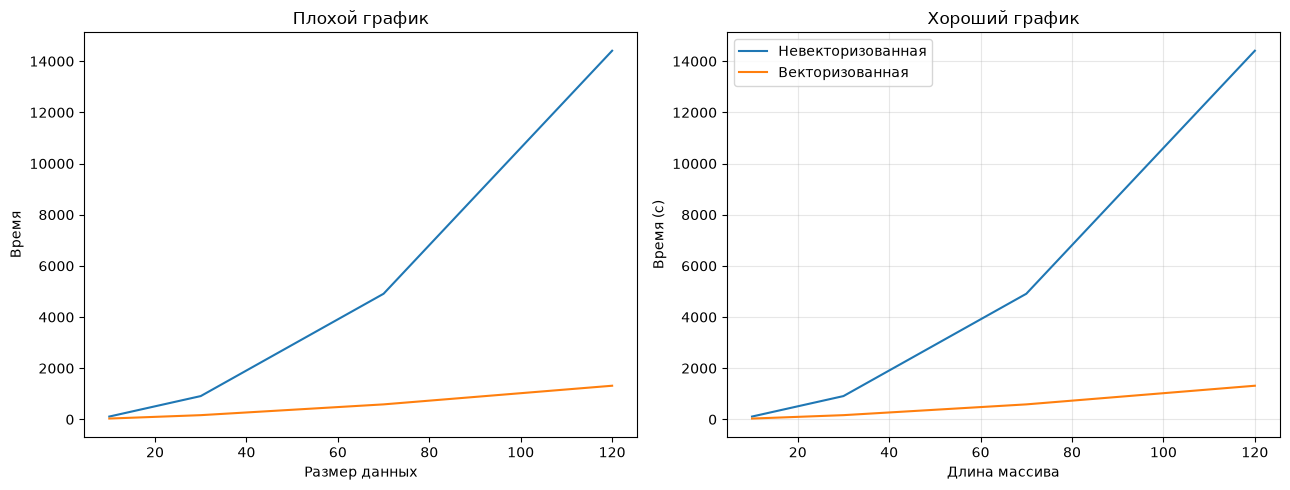

In [2]:
from importlib import reload

import matplotlib.pyplot as plt
import numpy as np

import functions
import functions_vectorized

%matplotlib inline


def reload_solution_modules():
    """Reload the two local solution modules after their files change."""
    reload(functions)
    reload(functions_vectorized)


data_size = np.array([10, 30, 70, 120])
time_non_vectorized = data_size**2 + 10
time_vectorized = data_size**1.5

figure, (axis_bad, axis_good) = plt.subplots(1, 2, figsize=(13, 5))

axis_bad.plot(data_size, time_non_vectorized)
axis_bad.plot(data_size, time_vectorized)
axis_bad.set_title("Плохой график")
axis_bad.set_xlabel("Размер данных")
axis_bad.set_ylabel("Время")

axis_good.plot(data_size, time_non_vectorized, label="Невекторизованная")
axis_good.plot(data_size, time_vectorized, label="Векторизованная")
axis_good.set_title("Хороший график")
axis_good.set_xlabel("Длина массива")
axis_good.set_ylabel("Время (с)")
axis_good.grid(True, alpha=0.3)
axis_good.legend()

figure.tight_layout()
plt.show()


* __Задача 1__: Подсчитать произведение ненулевых элементов на диагонали прямоугольной матрицы.  
 Например, для X = np.array([[1, 0, 1], [2, 0, 2], [3, 0, 3], [4, 4, 4]]) ответ – 3.

In [36]:
reload_solution_modules()

X = np.array([[1, 0, 1], [2, 0, 2], [3, 0, 3], [4, 4, 4]])
print(functions.prod_non_zero_diag(X.tolist()))
print(functions_vectorized.prod_non_zero_diag(X))

3
3


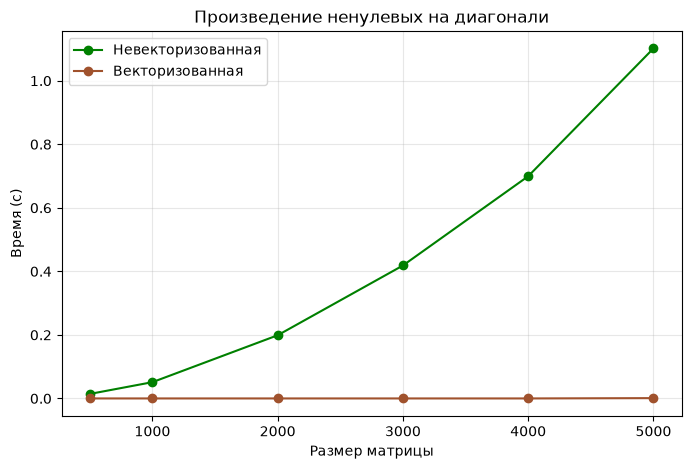

In [130]:
reload_solution_modules()
import time

s = [500, 1000, 2000, 3000, 4000, 5000]
ts = []
tf = []

for n in s:
    x = np.random.randn(n, n)

    t0 = time.time()
    functions.prod_non_zero_diag(x.tolist())
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.prod_non_zero_diag(x)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green',  label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Размер матрицы")
plt.ylabel("Время (с)")
plt.title("Произведение ненулевых на диагонали")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

 
 
* __Задача 2__: Даны два вектора x и y. Проверить, задают ли они одно и то же мультимножество.  
  Например, для x = np.array([1, 2, 2, 4]), y = np.array([4, 2, 1, 2]) ответ – True.
  
  


In [5]:
reload_solution_modules()

x = np.array([1, 2, 2, 4])
y = np.array([4, 2, 1, 2])
print(functions.are_multisets_equal(x.tolist(), y.tolist()))
print(functions_vectorized.are_multisets_equal(x, y))

True
True


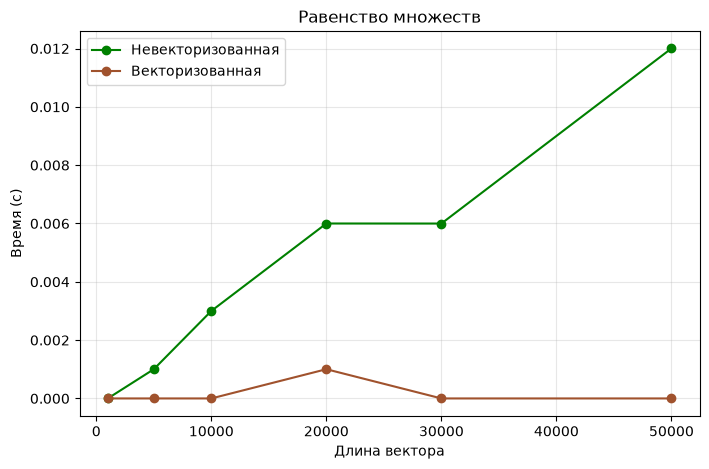

In [129]:
reload_solution_modules()
import time

s = [1000, 5000, 10000, 20000, 30000, 50000]
ts = []
tf = []

for n in s:
    x = np.random.randint(0, 10, n)
    y = np.random.randint(0, 10, n)

    t0 = time.time()
    functions.are_multisets_equal(x.tolist(), y.tolist())
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.are_multisets_equal(x, y)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green',label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Длина вектора")
plt.ylabel("Время (с)")
plt.title("Равенство множеств")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

* __Задача 3__: Найти максимальный элемент в векторе x среди элементов, перед которыми стоит нулевой.  
 Например, для x = np.array([6, 2, 0, 3, 0, 0, 5, 7, 0]) ответ – 5.

In [7]:
reload_solution_modules()

x = np.array([6, 2, 0, 3, 0, 0, 5, 7, 0])
print(functions.max_after_zero(x.tolist()))
print(functions_vectorized.max_after_zero(x))


5
5


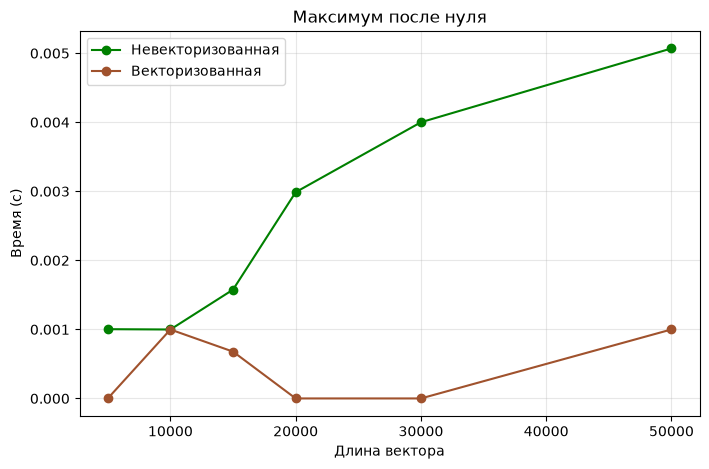

In [128]:
reload_solution_modules()
import time

s = [5000, 10000, 15000, 20000, 30000, 50000]
ts = []
tf = []

for n in s:
    x = np.random.randint(0, 5, n)

    t0 = time.time()
    functions.max_after_zero(x.tolist())
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.max_after_zero(x)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green', label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Длина вектора")
plt.ylabel("Время (с)")
plt.title("Максимум после нуля")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

 
 
* __Задача 4__: Дан трёхмерный массив, содержащий изображение, размера (height, width, numChannels), а также вектор длины numChannels. Сложить каналы изображения с указанными весами, и вернуть результат в виде матрицы размера (height, width). В ноутбуке приведите пример работы функции – преобразуйте цветное изображение в оттенки серого, использовав коэффициенты np.array([0.299, 0.587, 0.114]). Считать реальное изображение можно с помощью `PIL.Image.open` из пакета Pillow: `img = np.asarray(Image.open(path).convert("RGB"))`. Устаревшая функция `scipy.misc.imread` удалена из современных версий SciPy.


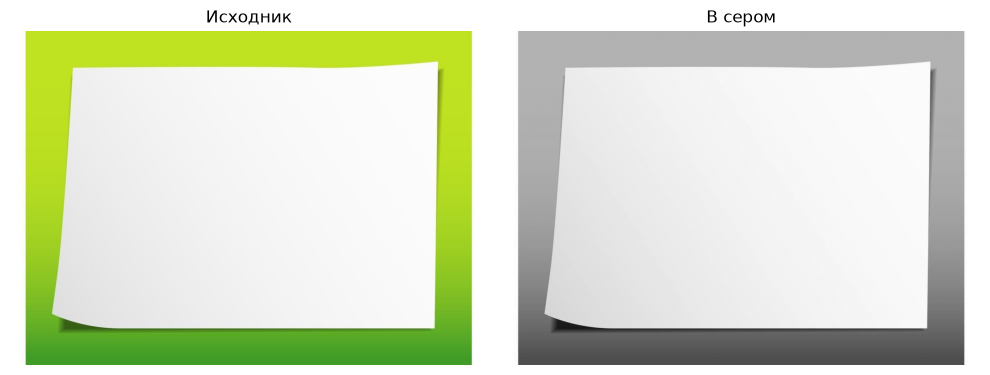

In [23]:
from PIL import Image

img = np.asarray(Image.open("white.jpg").convert("RGB"))
coefs = np.array([0.299, 0.587, 0.114])

gray = functions_vectorized.convert_image(img, coefs)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Исходник")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("В сером")
plt.axis("off")

plt.tight_layout()
plt.show()


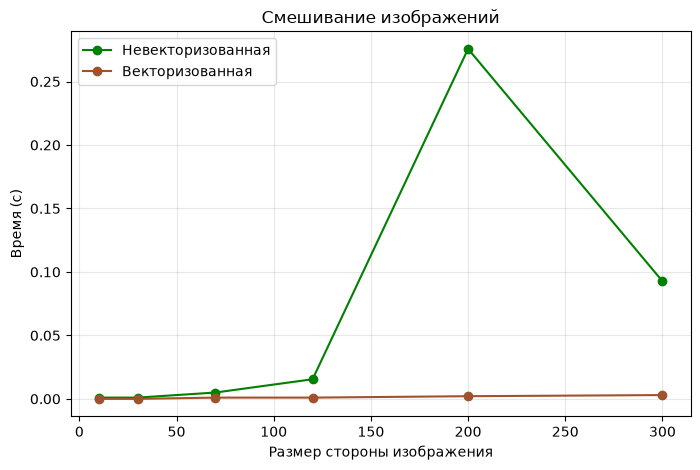

In [127]:
reload_solution_modules()
import time

s = [10, 30, 70, 120, 200, 300]
ts = []
tf = []

for n in s:
    img = np.random.randint(0, 255, (n, n, 3), dtype=np.uint8)
    coefs = np.array([0.299, 0.587, 0.114])

    t0 = time.time()
    functions.convert_image(img.tolist(), coefs.tolist())
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.convert_image(img, coefs)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green', label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Размер стороны изображения")
plt.ylabel("Время (с)")
plt.title("Смешивание изображений")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

* __Задача 5__: Реализовать кодирование длин серий (Run-length encoding). Для некоторого вектора x необходимо вернуть кортеж из двух векторов одинаковой длины. Первый содержит числа, а второй - сколько раз их нужно повторить.  
 Например, для x = np.array([2, 2, 2, 3, 3, 3, 5]) ответ – (np.array([2, 3, 5]), np.array([3, 3, 1])).

In [20]:
reload_solution_modules()

x = np.array([2, 2, 2, 3, 3, 3, 5])
a, s = functions_vectorized.run_length_encoding(x)
print(a, s)


[2 3 5] [3 3 1]


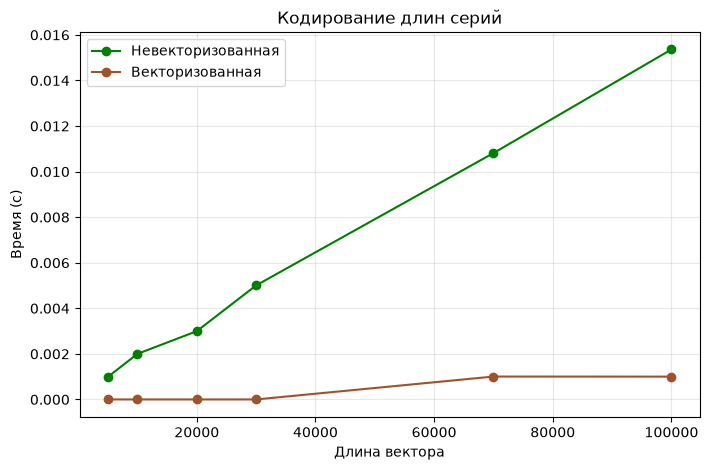

In [124]:
reload_solution_modules()
import time

s = [5000, 10000, 20000, 30000, 70000, 100000]
ts = []
tf = []

for n in s:
    x = np.random.randint(0, 3, n)


    t0 = time.time()
    functions.run_length_encoding(x.tolist())
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.run_length_encoding(x)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green', label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Длина вектора")
plt.ylabel("Время (с)")
plt.title("Кодирование длин серий")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

 
 
* __Задача 6__: Даны две выборки объектов - X и Y. Вычислить матрицу евклидовых расстояний между объектами. Дополнительно сравните с функцией scipy.spatial.distance.cdist по скорости работы (сравнения приведите ниже в ноутбуке).

In [54]:
from scipy.spatial.distance import cdist
reload_solution_modules()

x = np.random.randn(500, 20)
y = np.random.randn(400, 20)

t0 = time.time()
d1 = functions_vectorized.pairwise_distance(x, y)
t1 = time.time()

t2 = time.time()
d2 = cdist(x, y, metric="euclidean")
t3 = time.time()

print(f":  {t1 - t0:.4f} с")
print(f": {t3 - t2:.4f} с")
print(":", np.allclose(d1, d2))


:  0.0339 с
: 0.0040 с
: True


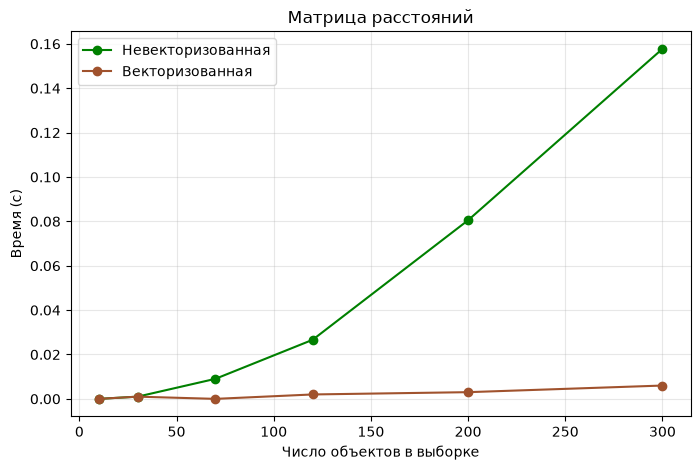

In [119]:
reload_solution_modules()
import time

s = [10, 30, 70, 120, 200, 300]
ts = []
tf = []

for n in s:
    x = np.random.randn(n, 5)
    y = np.random.randn(n, 5)
    x_list = x.tolist()
    y_list = y.tolist()

    t0 = time.time()
    functions.pairwise_distance(x_list, y_list)
    t1 = time.time()
    ts.append(t1 - t0)

    t2 = time.time()
    functions_vectorized.pairwise_distance(x, y)
    t3 = time.time()
    tf.append(t3 - t2)

plt.figure(figsize=(8, 5))
plt.plot(s, ts, marker="o",color = 'green', label="Невекторизованная")
plt.plot(s, tf, marker="o",color = 'sienna', label="Векторизованная")
plt.xlabel("Число объектов в выборке")
plt.ylabel("Время (с)")
plt.title("Матрица расстояний")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Туториал по Markdown

__(1 балл)__

Напишите краткий (а в данной домашке ещё и почти бесмысленный) отчёт с использованием 4-5 различных вариантов разметки/выделения текста.

# Отчёт по ДЗ

В работе мы реализовывали задачи **двумя способами** и сравнивали их эффективность на графиках:

1. Через обычные операции Python - *невекторизованная* реализация.
2. Без привычных функций Python, на векторах - *векторизованная* реализация.

---

| № | Задачи были такие |
|---|--------|
| 1 | Произведение ненулевых на диагонали |
| 2 | Равенство мультимножеств |
| 3 | Максимум после нуля |
| 4 | Смешивание каналов |
| 5 | Кодирование длин серий |
| 6 | Матрица расстояний |

---

Оказалось, что **векторный способ даёт выигрыш по скорости**, но чаще всего уже на больших числах.

> На малых значениях разница может быть не видна, или же векторный способ будет работать ~~лучше~~ **хуже** обычного.
